In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import qmc, multivariate_normal
import matplotlib.pyplot as plt
from data_l63_v1 import create_and_save_dataset, load_dataset_loaders
import torch
from ml_models import ConditionalNF, train_conditional_nf, ConditionalNF_LSTM, ConditionalNF_LSTM_ANN
from util_ml import *
from inference_util import evaluate_conditional_nf
import json
import sys

# Load the dataset-
Only run this if you need new dataset, otherwise jump to the next block

# Define the model and training parameters

In [3]:
models_dict = {}


In [ ]:
def normalize_parameters_l63(x_true, x_samples):
    """
    Normalize the L63 parameters to the range [0, 1] based on known min and max values.
    
    Args:
        x_true: shape (ncc, nfeatures)
        x_samples: shape (ncc, nsample, nfeatures)
    """
    # Compute per-feature min and max from the true data
    x_min = x_true.min(axis=0)          # shape: (nfeatures,)
    x_max = x_true.max(axis=0)          # shape: (nfeatures,)
    scale = x_max - x_min               # shape: (nfeatures,)
    print(x_min.shape)

    # Avoid divide-by-zero for constant features
    scale[scale == 0] = 1.0

    # Normalize x_true to [0, 1]
    x_true_norm = (x_true - x_min) / scale  # shape: (ncc, nfeatures)

    # Normalize x_samples using the SAME scaling
    # x_samples: (ncc, nsample, nfeatures)
    # We need to broadcast x_min and scale across the nsample dimension (axis=1)
    x_min_expanded = x_min[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)
    scale_expanded = scale[np.newaxis, np.newaxis, :]    # (1, 1, nfeatures)

    x_samples_norm = (x_samples - x_min_expanded) / scale_expanded
    return x_true_norm, x_samples_norm


# Loop over all combinations
casees = ['easy', 'intermediate', 'hard']
casees = ['easy']

for T_window, dt_subsample in recommended_combinations:
    for case in casees:
        print(f"\n{'='*60}")
        print(f"Loading model for T_window={T_window}, dt_subsample={dt_subsample}")
        print(f"{'='*60}\n")
        
        # Load dataset
        # Load dataset
        train_loader, test_loader = load_dataset_loaders(
            f"./data/l63_LATENT_GMM_dt1_T200_w28_{case}.npz", 
            batch_size=128,
            T_window=T_window,
            dt=dt_subsample,
            direcet_params=False,
            avg=False   
        )
        
        # Load configuration
        json_path = ""
        json_full_path = os.path.join(json_path, "L63_config_latent_params_v0.json")
        with open(json_full_path, 'r') as f:
            config = json.load(f)
        
        network_params = config["network_params"]
        train_params = config["training_params"]
        
        # Update parameters
        network_params['hidden_dims'] = [64, 128, 128]
        n_time = int(T_window / dt_subsample + 0.1)
        network_params["n_time"] = n_time
        
        # Define paths and names
        run_name = f"ANN_l63_LATENT_GMM_dt{dt_subsample}_T{T_window}_w28_{case}"
        checkpoint_path = f"./save_models/nflow_{run_name}.pt"
        
        print(f"Run name: {run_name}")
        print(f"Checkpoint path: {checkpoint_path}")
        
        # Configure device
        device_id = train_params["device_id"]
        device = configure_device(device_id)
        
        # Initialize model
        model = ConditionalNF(**network_params).to(device)
        optimizer = torch.optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=train_params["learning_rate"],
            weight_decay=train_params["weight_decay"]
        )
        
        # Load from checkpoint
        model = load_from_checkpoint(model, optimizer, checkpoint_path, device)
        model.eval()  # Set to evaluation mode

        _ , c_vals, x_true, x_samples = evaluate_conditional_nf(model, test_loader, device=device, n_samples=300)
        #normalize to 0,1 
        x_true, x_samples = normalize_parameters_l63(x_true, x_samples)
        
        # Store model and dataloaders with key

        key = f"T{T_window}_dt{dt_subsample}_{case}"
        models_dict[key] = {
            'model': model,
            'test_loader': test_loader,
            'network_params': network_params,
            'run_name': run_name,
            'T_window': T_window,
            'dt_subsample': dt_subsample,
            'device': device,
            'conditionals':c_vals,
            'params_true': x_true,
            'params_generated':x_samples

        }
        
        print(f"Successfully loaded model: {key}\n")



Loading model for T_window=20, dt_subsample=2

Run name: ANN_l63_LATENT_GMM_dt2_T20_w28_easy
Checkpoint path: ./save_models/nflow_ANN_l63_LATENT_GMM_dt2_T20_w28_easy.pt
CUDA not available. Using CPU.
 Loaded checkpoint './save_models/nflow_ANN_l63_LATENT_GMM_dt2_T20_w28_easy.pt'
Average NLL on evaluation set: -0.3047
(5,)
Successfully loaded model: T20_dt2_easy


Loading model for T_window=50, dt_subsample=2

Run name: ANN_l63_LATENT_GMM_dt2_T50_w28_easy
Checkpoint path: ./save_models/nflow_ANN_l63_LATENT_GMM_dt2_T50_w28_easy.pt
CUDA not available. Using CPU.
 Loaded checkpoint './save_models/nflow_ANN_l63_LATENT_GMM_dt2_T50_w28_easy.pt'
Average NLL on evaluation set: 3.7003
(5,)
Successfully loaded model: T50_dt2_easy



In [87]:
import matplotlib.pyplot as plt
import numpy as np

def plot_parameter_scatter(x_true, x_samples,run_name,save = False):
    """
    Plots histograms of true vs predicted parameters for all features.
    
    Args:
        x_true: numpy array of true parameters, shape (N, x_dim)
        x_samples: numpy array of samples, shape (N, n_samples, x_dim) or (n_samples, N, x_dim)
    """
    param_name = ['sigma', 'rho', 'betta']
    # Ensure shape is (N, n_samples, x_dim)
    if x_samples.shape[0] != x_true.shape[0]:
        x_samples = np.transpose(x_samples, (1, 0, 2))

    x_pred_mean = np.mean(x_samples, axis=1)  # mean over samples

    n_features = x_true.shape[1]
    fig, axes = plt.subplots(1, 2, figsize=(5*n_features, 4))

    

    axes[0].scatter(x_pred_mean[:, 1], x_pred_mean[:, 2],alpha=0.5, label='Predicted')
    axes[0].scatter(x_true[:, 1],x_true[:, 2],  alpha=0.5, label='True')

    axes[0].set_ylabel('beta')
    axes[0].set_xlabel('rho')
    axes[0].legend()


    axes[1].scatter(x_pred_mean[:, 0], x_pred_mean[:, 2],alpha=0.5, label='Predicted')
    axes[1].scatter(x_true[:, 0],x_true[:, 2],  alpha=0.5, label='True')
    
    axes[1].set_ylabel('beta')
    axes[1].set_xlabel('sigma')
    
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    if save:
        fig.savefig(f"./plots/{run_name}_scatter.jpeg",bbox_inches = 'tight',dpi  =100)
def plot_parameter_histograms(x_true, x_samples,run_name,save = False, theta_params = False):
    """
    Plots histograms of true vs predicted parameters for all features.
    
    Args:
        x_true: numpy array of true parameters, shape (N, x_dim)
        x_samples: numpy array of samples, shape (N, n_samples, x_dim) or (n_samples, N, x_dim)
    """
    param_name = ['sigma', 'rho', 'betta']
    param_name = ['theta_1', 'theta_2', 'theta_3', 'theta_4', 'theta_5']
    # Ensure shape is (N, n_samples, x_dim)
    if x_samples.shape[0] != x_true.shape[0]:
        x_samples = np.transpose(x_samples, (1, 0, 2))

    x_pred_mean = np.mean(x_samples, axis=1)  # mean over samples
    x_pred_mean = x_samples[:,10,:]
    n_features = x_true.shape[1]
    fig, axes = plt.subplots(1, n_features, figsize=(5*n_features, 4))

    if n_features == 1:
        axes = [axes]  # ensure iterable if only one feature

    for i in range(1,n_features):
        axes[i].hist(x_true[:, i], bins=50, alpha=0.5, label='True', density=True)
        axes[i].hist(x_pred_mean[:, i], bins=50, alpha=0.5, label='Predicted', density=True)
        axes[i].set_title(f'Parameter: {param_name[i]}', fontsize=15)
        axes[i].legend()
        axes[i].tick_params(axis='both', which='major', labelsize=14)
        axes[i].set_xlim(-0.5,1.5)


    if theta_params:
        axes[0].hist((x_true[:, 1] + x_true[:, 0])/2, bins=50, alpha=0.5, label='True', density=True)
        axes[0].hist((x_pred_mean[:, 1] + x_pred_mean[:, 0])/2, bins=50, alpha=0.5, label='True', density=True)
        axes[0].tick_params(axis='both', which='major', labelsize=14)
        axes[0].set_title(f'Parameter: {param_name[0]}', fontsize=15)
        axes[0].set_xlim(-0.5,1.5)

        
    plt.tight_layout()
    plt.show()
    if save:
        fig.savefig(f"./plots/{run_name}_hist.jpeg",bbox_inches = 'tight',dpi  =100)


T20_dt2_easy


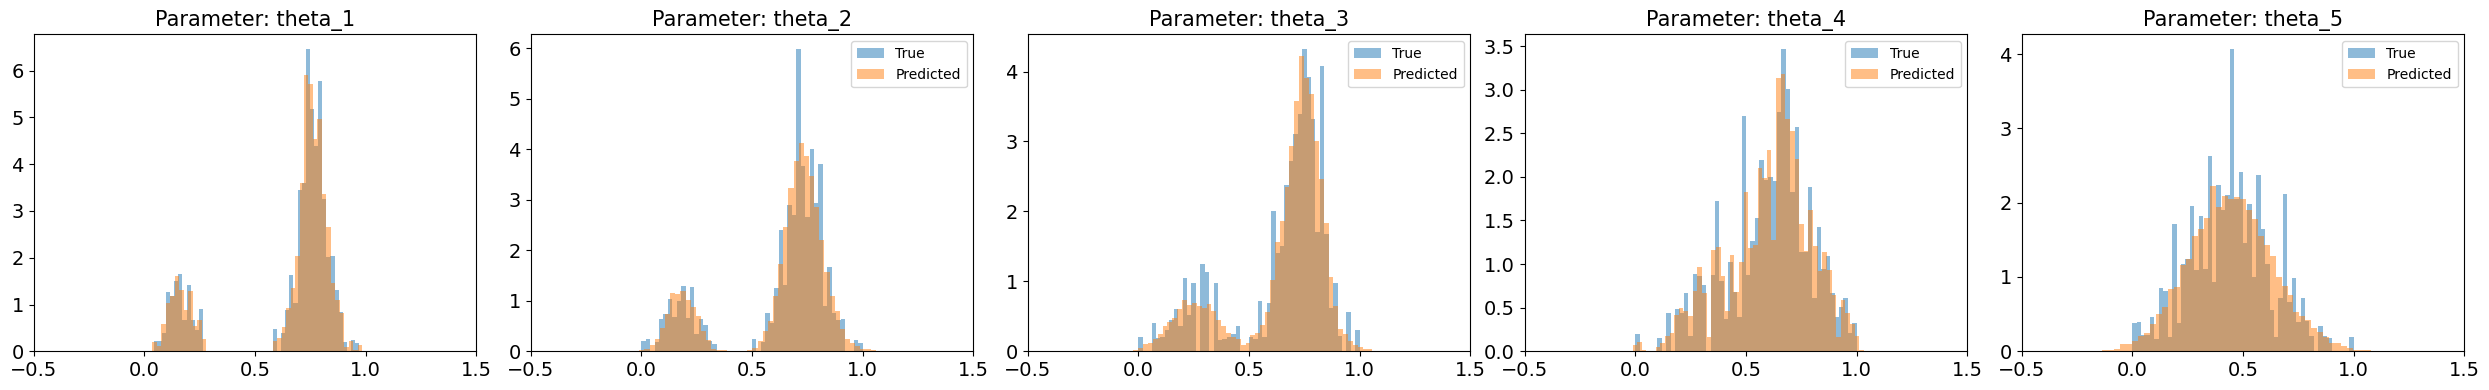

T20_dt2_intermediate


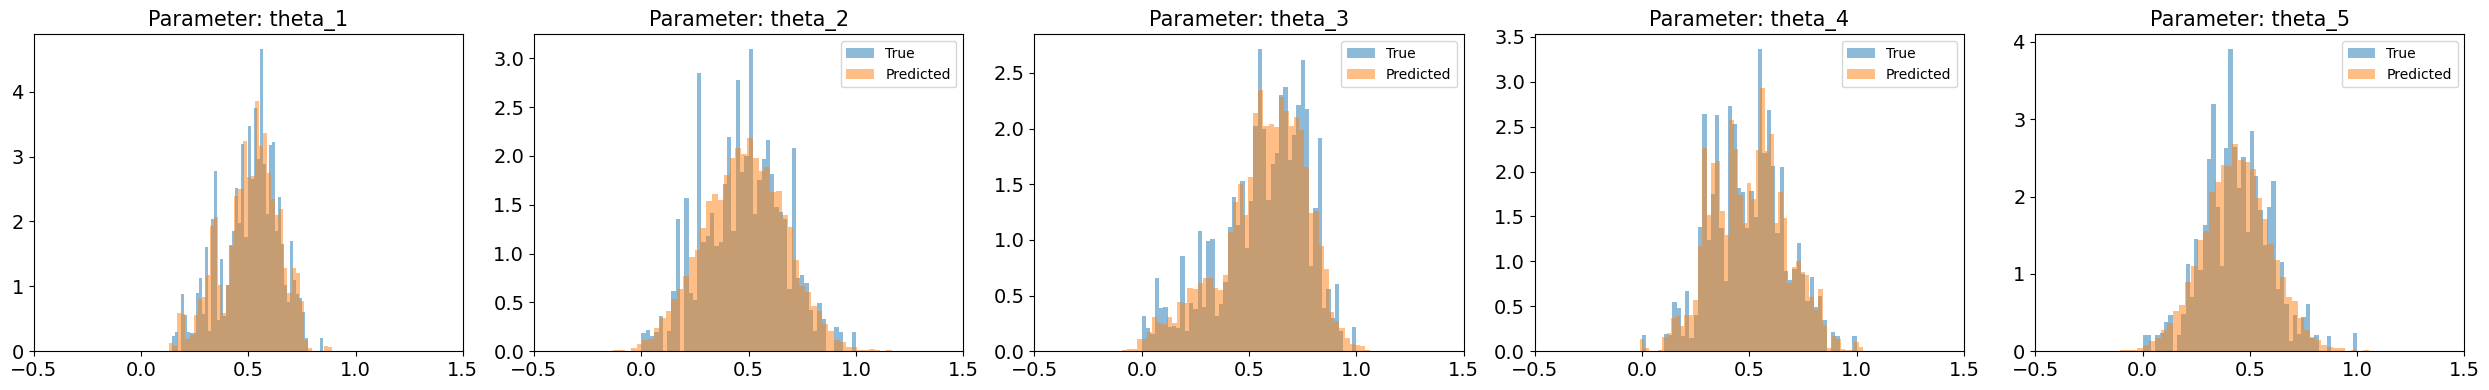

T20_dt2_hard


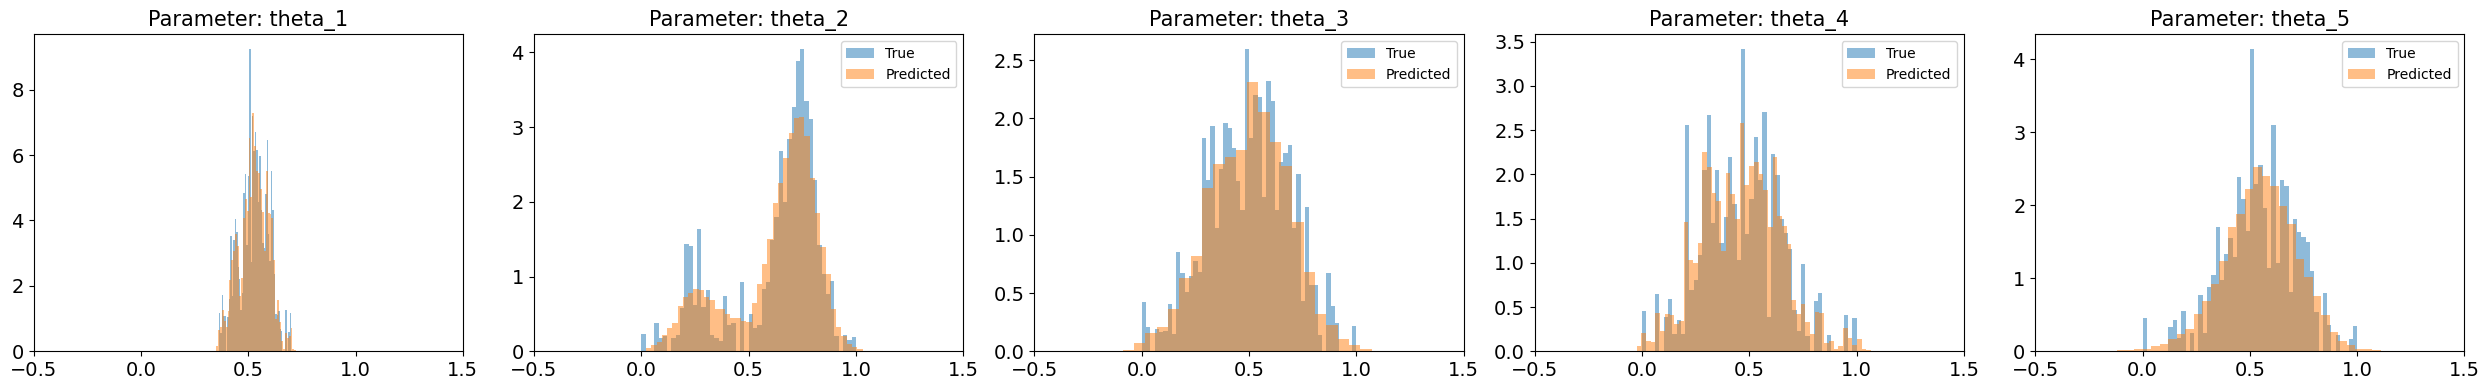

T50_dt5_easy


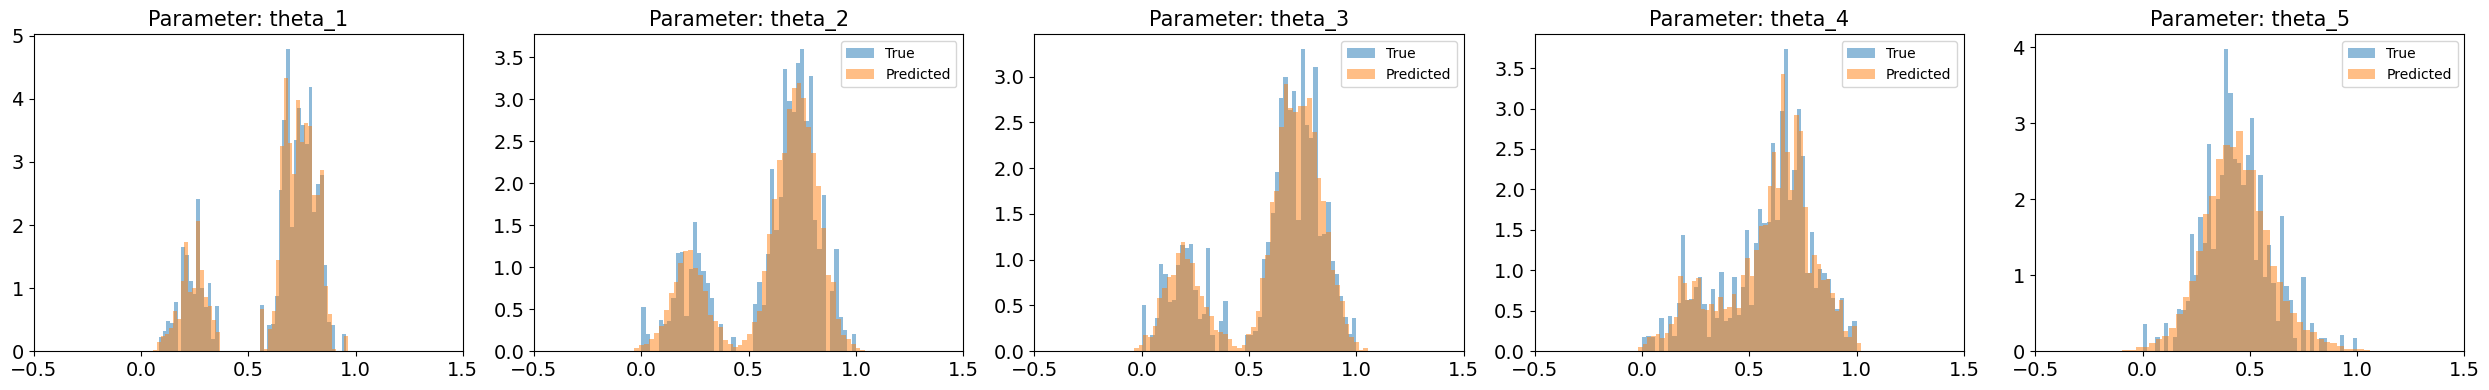

T50_dt5_intermediate


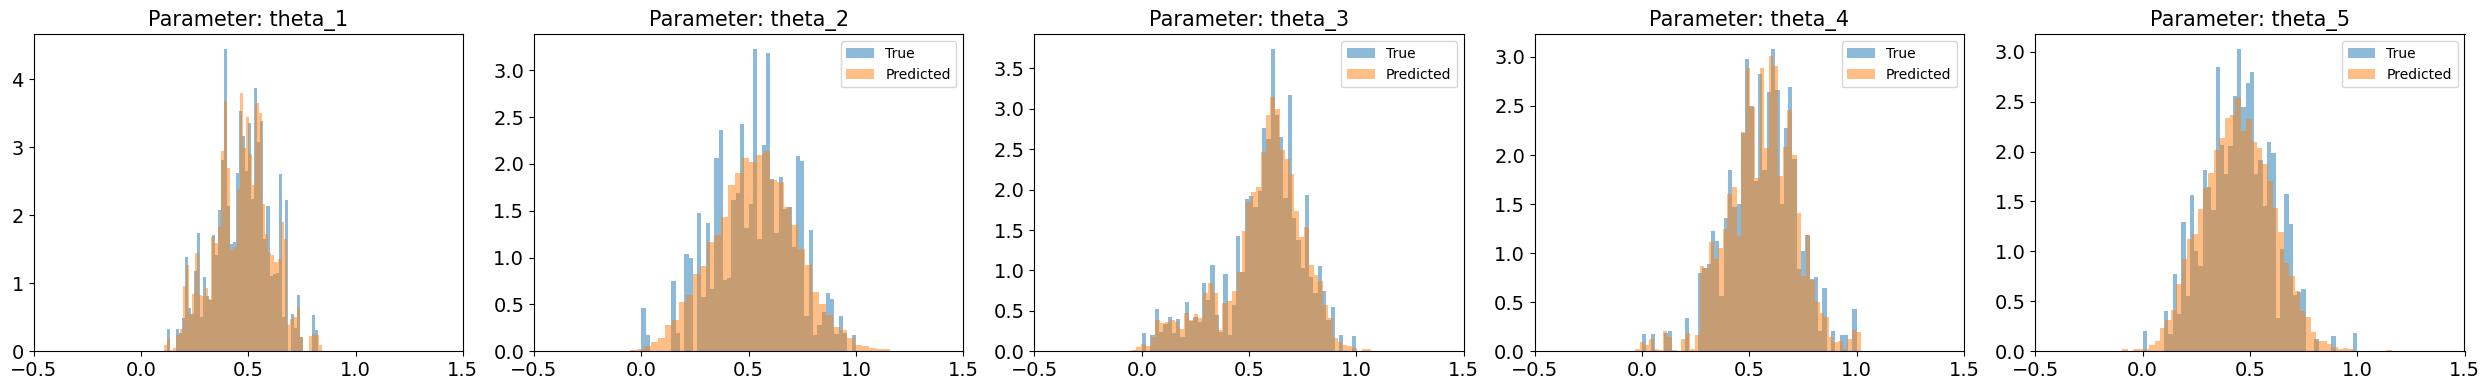

T50_dt5_hard


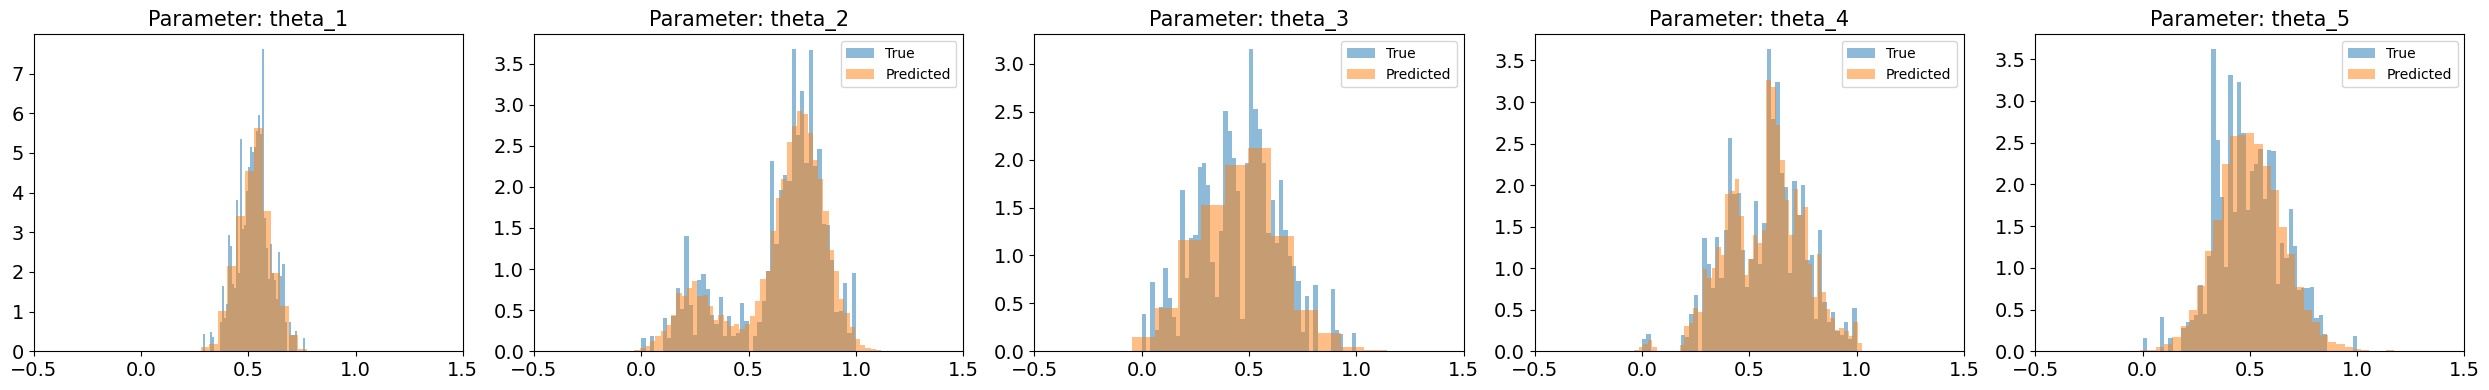

T200_dt200_easy


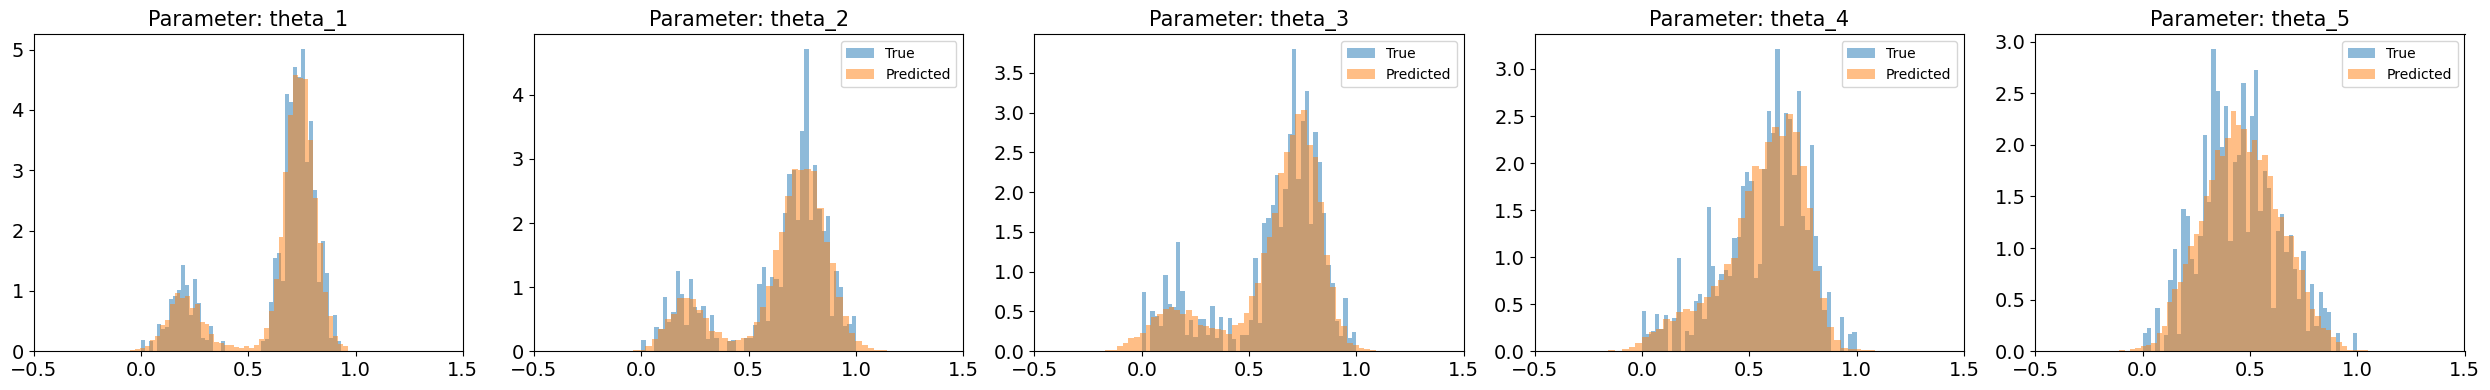

(10240, 5)

In [105]:
for key in models_dict.keys():
    print (key)
    plot_parameter_histograms(models_dict[key]["params_true"], models_dict[key]["params_generated"],key,save = False, theta_params = True)
x_true.shape

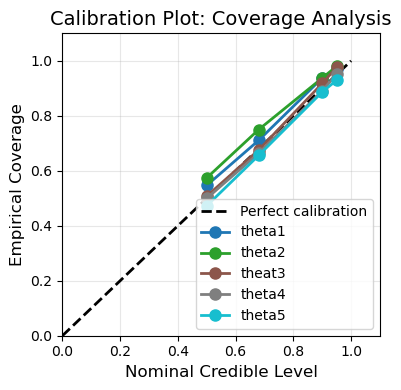

In [108]:
def compute_coverage_analysis(models_dict, key, credible_levels=[0.5, 0.68, 0.90, 0.95]):
    """
    Compute empirical coverage for different credible intervals
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing params_true and params_generated
    key : str
        Key to access the model data
    credible_levels : list
        List of credible levels to compute (e.g., 0.95 for 95% CI)
    
    Returns:
    --------
    coverage_results : dict
        Dictionary with coverage statistics for each parameter
    """
    params_true = models_dict[key]["params_true"]
    params_generated = models_dict[key]["params_generated"]
    
    n_trajectories, n_samples, n_params = params_generated.shape
    
    # Find unique true parameter sets
    unique_params, inverse_indices = np.unique(params_true, axis=0, return_inverse=True)
    n_unique = len(unique_params)
    
    # Storage for coverage results
    coverage_results = {level: np.zeros((n_unique, n_params)) for level in credible_levels}
    
    # For each unique parameter set
    for idx in range(n_unique):
        # Find all trajectories with this parameter set
        traj_indices = np.where(inverse_indices == idx)[0]
        
        # For each parameter dimension
        for param_idx in range(n_params):
            true_value = unique_params[idx, param_idx]
            
            # Collect posterior samples from all trajectories with same true params
            all_posterior_samples = params_generated[traj_indices, :, param_idx].flatten()
            
            # Compute credible intervals
            for level in credible_levels:
                alpha = (1 - level) / 2
                lower = np.percentile(all_posterior_samples, alpha * 100)
                upper = np.percentile(all_posterior_samples, (1 - alpha) * 100)
                
                # Check if true value is within interval
                coverage_results[level][idx, param_idx] = (lower <= true_value <= upper)
    
    # Compute empirical coverage (fraction of times true value is in interval)
    empirical_coverage = {level: np.mean(coverage_results[level], axis=0) 
                          for level in credible_levels}
    
    return empirical_coverage, credible_levels


def plot_calibration(empirical_coverage, credible_levels, param_labels):
    """
    Plot calibration curve showing empirical vs nominal coverage
    """
    fig, ax = plt.subplots(figsize=(4, 4))
    
    n_params = len(param_labels)
    colors = plt.cm.tab10(np.linspace(0, 1, n_params))
    
    # Plot diagonal (perfect calibration)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect calibration')
    
    # Plot each parameter
    for param_idx in range(n_params):
        coverages = [empirical_coverage[level][param_idx] for level in credible_levels]
        ax.plot(credible_levels, coverages, 'o-', linewidth=2, markersize=8,
                color=colors[param_idx], label=param_labels[param_idx])
    
    ax.set_xlabel('Nominal Credible Level', fontsize=12)
    ax.set_ylabel('Empirical Coverage', fontsize=12)
    ax.set_title('Calibration Plot: Coverage Analysis', fontsize=14)
    ax.legend(fontsize=10,loc='lower right')
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1.1])
    ax.set_ylim([0, 1.1])
    
    plt.tight_layout()
    return fig


# Usage
key = keys[-1]
param_labels = ['theta1', 'theta2', 'theat3', 'theta4', 'theta5']

empirical_coverage, credible_levels = compute_coverage_analysis(
    models_dict, key, credible_levels=[0.5, 0.68, 0.90, 0.95]
)

fig = plot_calibration(empirical_coverage, credible_levels, param_labels)
plt.savefig(f'./plots/calibration_plot_{key}.png', dpi=300, bbox_inches='tight')
plt.show()

# # Print numerical results
# print("Empirical Coverage Results:")
# for level in credible_levels:
#     print(f"\n{level*100:.0f}% Credible Interval:")
#     for i, label in enumerate(param_labels):
#         print(f"  {label}: {empirical_coverage[level][i]:.3f}")

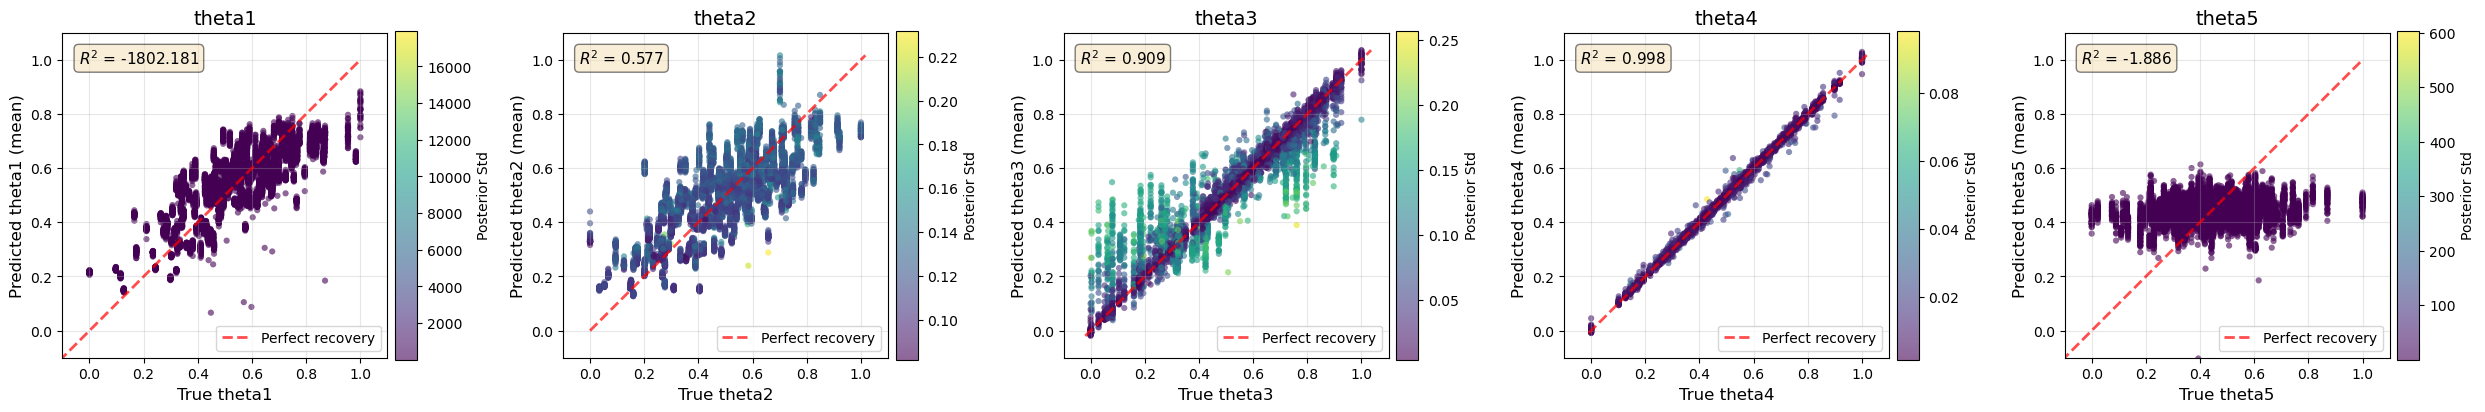


Parameter Recovery Statistics:


In [122]:
def plot_parameter_recovery(models_dict, key, param_labels):
    """
    Plot true vs predicted parameters for all trajectory-parameter pairs
    
    Parameters:
    -----------
    models_dict : dict
        Dictionary containing params_true and params_generated
    key : str
        Key to access the model data
    param_labels : list
        List of parameter names
    
    Returns:
    --------
    fig : matplotlib figure
    """
    params_true = models_dict[key]["params_true"]
    params_generated = models_dict[key]["params_generated"]
    
    n_trajectories, n_samples, n_params = params_generated.shape
    
    # Compute posterior mean for each trajectory
    params_predicted_mean = np.mean(params_generated, axis=1)  # shape: (n_trajectories, n_params)
    
    # Compute posterior std for color coding
    params_predicted_std = np.std(params_generated, axis=1)  # shape: (n_trajectories, n_params)
    
    # Create subplots
    fig, axes = plt.subplots(1, n_params, figsize=(5*n_params, 5))
    
    if n_params == 1:
        axes = [axes]
    
    for i, (ax, label) in enumerate(zip(axes, param_labels)):
        # Scatter plot: true vs predicted
        scatter = ax.scatter(params_true[:, i], params_predicted_mean[:, i], 
                           c=params_predicted_std[:, i], 
                           alpha=0.6, s=20, cmap='viridis', edgecolors='none')
        
        # Add diagonal line (perfect recovery)
        min_val = min(params_true[:, i].min(), params_predicted_mean[:, i].min())
        max_val = max(params_true[:, i].max(), params_predicted_mean[:, i].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, 
                label='Perfect recovery', alpha=0.7)
        
        # Labels and formatting
        ax.set_xlabel(f'True {label}', fontsize=12)
        ax.set_ylabel(f'Predicted {label} (mean)', fontsize=12)
        ax.set_title(f'{label}', fontsize=14)
        ax.legend(fontsize=10)
        ax.grid(alpha=0.3)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim([-0.1, 1.1])

        
        # Add colorbar
        cbar = plt.colorbar(scatter, ax=ax, pad=0.02,aspect=15, shrink=0.7)
        cbar.set_label('Posterior Std', fontsize=10)
        
        # Compute and display R² score
        from sklearn.metrics import r2_score
        r2 = r2_score(params_true[:, i], params_predicted_mean[:, i])
        ax.text(0.05, 0.95, f'$R^2$ = {r2:.3f}', 
                transform=ax.transAxes, fontsize=11,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    return fig


# Usage
key = keys[1]
param_labels = ['theta1', 'theta2', 'theta3', 'theta4', 'theta5']

fig = plot_parameter_recovery(models_dict, key, param_labels)
plt.savefig(f'parameter_recovery_{key}.png', dpi=300, bbox_inches='tight')
plt.show()

# Optional: Compute additional statistics
print("\nParameter Recovery Statistics:")
params_true = models_dict[key]["params_true"]
params_predicted_mean = np.mean(models_dict[key]["params_generated"], axis=1)

# for i, label in enumerate(param_labels):
#     mae = np.mean(np.abs(params_true[:, i] - params_predicted_mean[:, i]))
#     rmse = np.sqrt(np.mean((params_true[:, i] - params_predicted_mean[:, i])**2))
#     print(f"\n{label}:")
#     print(f"  MAE: {mae:.4f}")
#     print(f"  RMSE: {rmse:.4f}")

In [52]:
import corner
import numpy as np
import matplotlib.pyplot as plt

def compare_posteriors(nflow_samples, true_samples, labels=None, 
                      truths=None, figsize=(10, 10)):
    """
    Compare NFlow posterior with true Bayesian posterior.
    
    Args:
        nflow_samples: samples from normalizing flow (n_samples, n_params)
        true_samples: samples from MCMC/true Bayesian (n_samples, n_params)
        labels: parameter names
        truths: true parameter values
    """
    if labels is None:
        labels = ['σ', 'ρ', 'β']
    
    # Create figure
    fig = corner.corner(
        true_samples,
        labels=labels,
        color='red',
        alpha=0.6,
        hist_kwargs={'density': True, 'alpha': 0.6},
        label='true density',
        truths=truths,
        truth_color='black',
        show_titles=False,
        smooth=1.0,
        levels=(0.68, 0.95),  # 1σ and 2σ contours
        plot_datapoints=False,  # Don't show individual points
        fill_contours=True,
        range=[(-0.3, 1.3) for _ in labels],
        figsize=figsize
    )
    
    # Overlay NFlow samples
    corner.corner(
        nflow_samples,
        fig=fig,
        color='blue',
        alpha=0.6,
        hist_kwargs={'density': True, 'alpha': 0.6},
        label='NFlow estimation',
        smooth=1.0,
        levels=(0.68, 0.95),
        plot_datapoints=False,
        fill_contours=True,
        range=[(-0.3, 1.3) for _ in labels]
    )
    
    # Add legend
    axes = np.array(fig.axes).reshape((len(labels), len(labels)))
    axes[0, -1].legend(loc='upper right', fontsize=12, frameon=True)
    


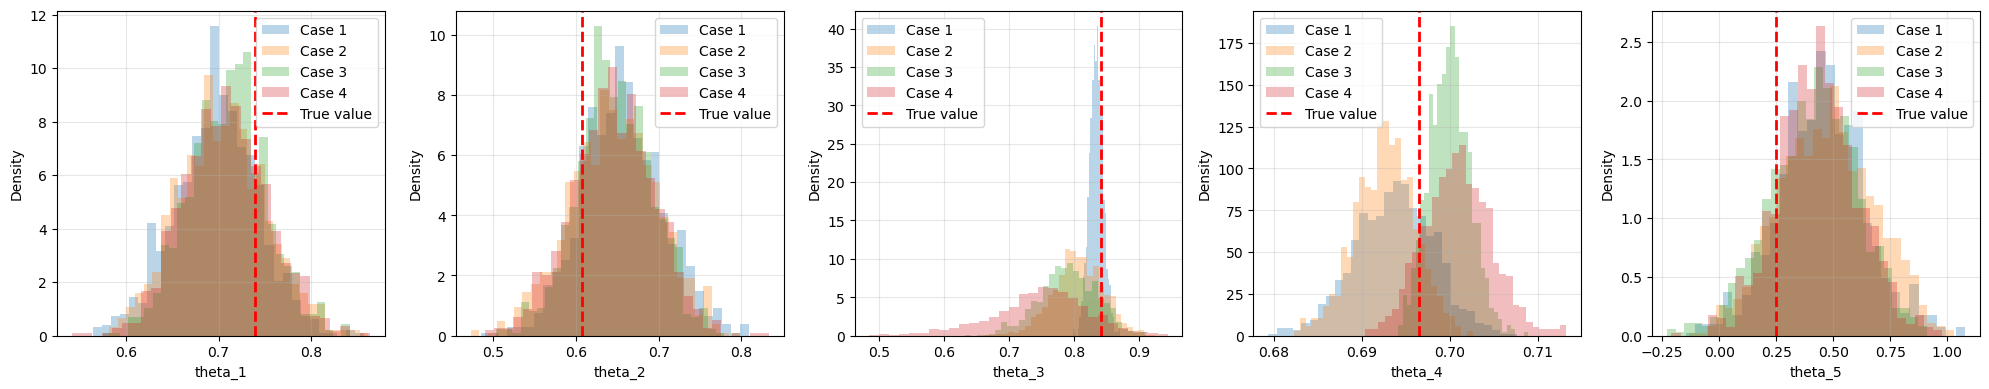

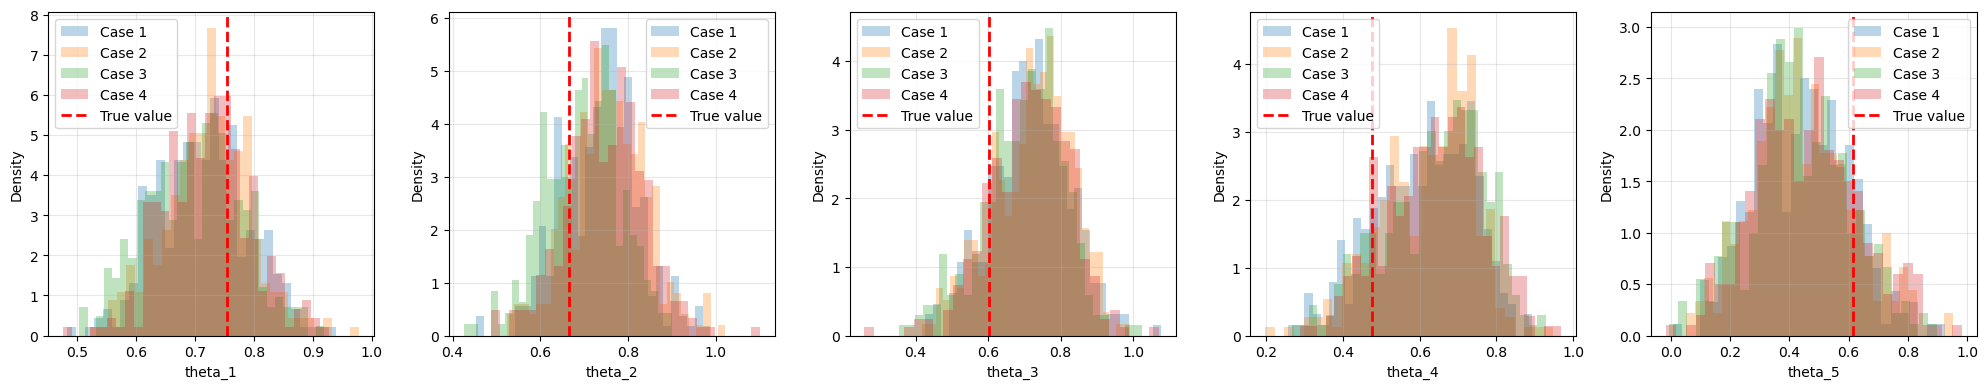

In [111]:
def compare_posteriors_same_params(params , labels, truths, **kwargs):
    """
    Compare posterior distributions from multiple trajectories
    
    params1, params2: arrays of shape (n_samples, n_params)
    labels: list of parameter names
    truths: true parameter values
    """
    n_params = len(labels)
    fig, axes = plt.subplots(1, n_params, figsize=(4*n_params, 4))
    n_cases = params.shape[0]
    if n_params == 1:
        axes = [axes]

    for i, (ax, label) in enumerate(zip(axes, labels)):
        for j in range(n_cases):
            ax.hist(params[j,:, i], bins=30, alpha=0.3, label=f'Case {j+1}', density=True)
        
        # Add vertical line for true value
        ax.axvline(truths[i], color='red', linestyle='--', linewidth=2, label='True value')
        
        ax.set_xlabel(label)
        ax.set_ylabel('Density')
        ax.legend()
        ax.grid(alpha=0.3)
    
    plt.tight_layout()
    return fig

for key in [keys[0],keys[-1]]:
# key = keys[0]
    def return_indexes(key,n_samples=2):
        
        # Find all unique parameter sets
        unique_params, inverse_indices = np.unique(
            models_dict[key]["params_true"], 
            axis=0, 
            return_inverse=True
        )

        # Select a random unique parameter set
        selected_idx = np.random.randint(len(unique_params))
        selected_param = unique_params[selected_idx]

        # Find all trajectories with this parameter set
        matching_trajectories = np.where(inverse_indices == selected_idx)[0]

        # Pick a few trajectories (e.g., 2-3 random ones)
        n_samples = min(n_samples, len(matching_trajectories))
        selected_cases = np.random.choice(matching_trajectories, size=n_samples, replace=False)
        return selected_cases, selected_param
    selected_cases, selected_param = return_indexes(key,n_samples=4)
    # Plot comparison for first two
    fig = compare_posteriors_same_params(
        models_dict[key]["params_generated"][selected_cases[0:4],:,:], 
        # models_dict[key]["params_generated"][selected_cases[1],:,:],
        labels=['theta_1','theta_2','theta_3','theta_4','theta_5'],
        truths=selected_param,
    )
    plt.savefig('./plots/comparison.png', dpi=300, bbox_inches='tight')

In [46]:
len(selected_cases)

47

/var/folders/hk/xkrk0v955zd07l64bknl6h040000gp/T/ipykernel_17313/3995948533.py:55: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, -1].legend(loc='upper right', fontsize=12, frameon=True)


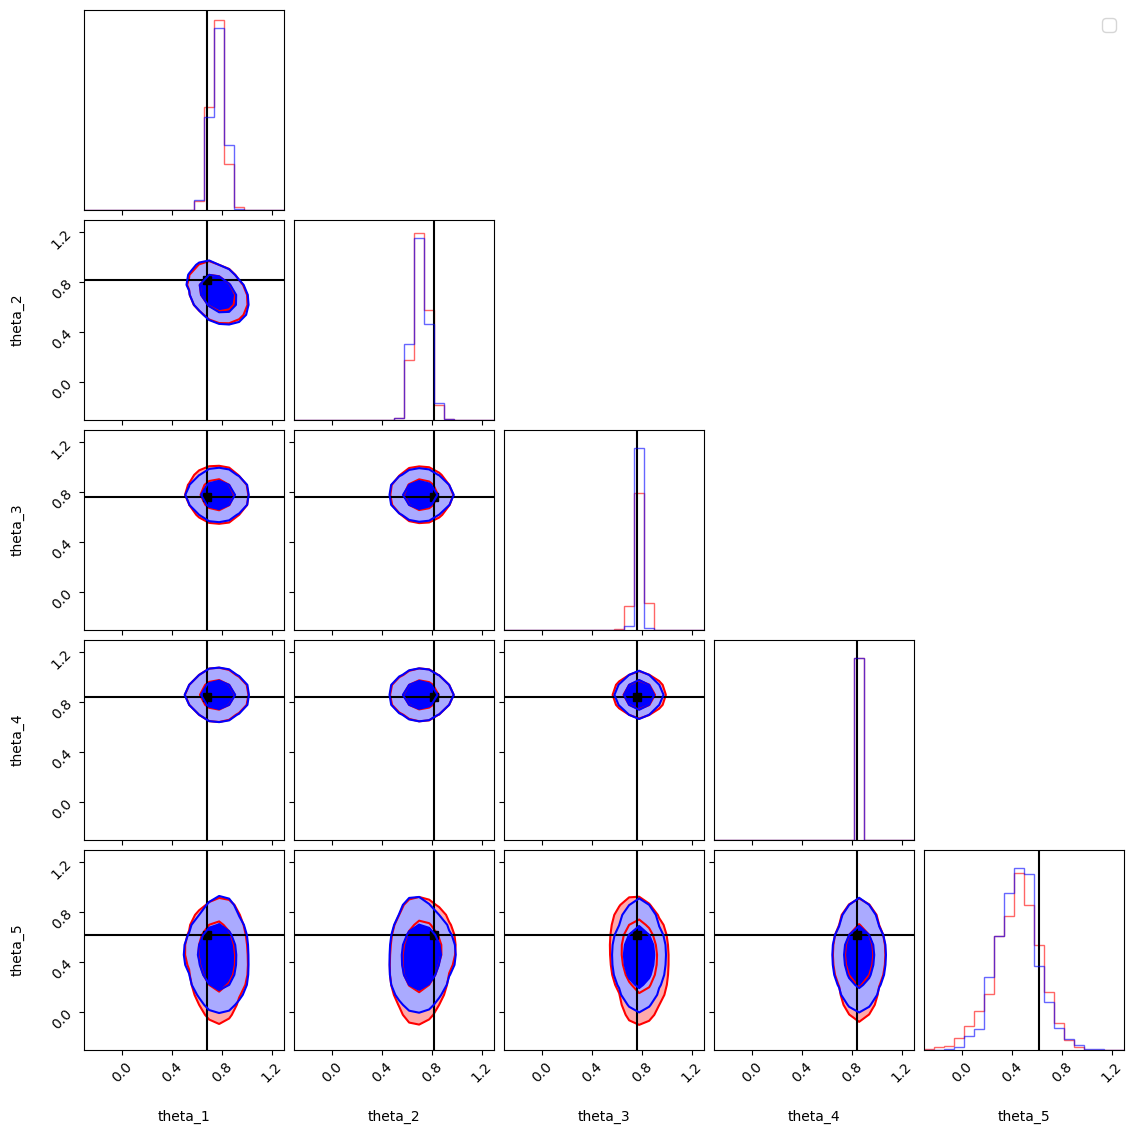

In [123]:

for key in [keys[0]]:
    selected_cases, selected_param = return_indexes(key,n_samples=50)
    # case = selected_cases[10]
    # 2. Visual comparison
    fig = compare_posteriors(
        models_dict[key]["params_generated"][selected_cases[10],:,:], models_dict[key]["params_generated"][selected_cases[31],:,:],
        labels=['theta_1','theta_2','theta_3','theta_4','theta_5'],
        truths=selected_param,
    )
    plt.savefig(f'./plots/corners_comparison{key}.png', dpi=300, bbox_inches='tight')


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde

def _kde1d(x, grid=None, bw=None):
    x = np.asarray(x).ravel()
    if grid is None:
        lo, hi = np.percentile(x, [0.5, 99.5])
        grid = np.linspace(lo, hi, 300)
    kde = gaussian_kde(x, bw_method=bw)
    return grid, kde(grid)

def _kde2d(x, y, xgrid=None, ygrid=None, bw=None):
    xy = np.vstack([x.ravel(), y.ravel()])
    kde = gaussian_kde(xy, bw_method=bw)
    if xgrid is None:
        xgrid = np.linspace(*np.percentile(x, [0.5, 99.5]), 150)
    if ygrid is None:
        ygrid = np.linspace(*np.percentile(y, [0.5, 99.5]), 150)
    xx, yy = np.meshgrid(xgrid, ygrid)
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    return xx, yy, zz

def compare_posteriors_panels(nflow_samples, true_samples, labels=None,
                              truths=None, figsize=8, fontsize = 16,
                              tick_labelsize=16,savepath=None,
                              levels=(0.68, 0.95), bins=40, hexbin_gridsize=35):
    """
    Minimalist joint view:
      - diagonal: 1D KDEs (true vs flow)
      - lower-tri: hexbin (flow) + contour (true)
    """
    nflow_samples = np.asarray(nflow_samples)
    true_samples  = np.asarray(true_samples)
    assert nflow_samples.shape[1] == true_samples.shape[1], "Dim mismatch."

    D = nflow_samples.shape[1]
    if labels is None:
        labels = [f"θ{j+1}" for j in range(D)]

    fig = plt.figure(figsize=(figsize, figsize))
    gs = GridSpec(D, D, figure=fig, wspace=0.15, hspace=0.15)

    contour_levels = 5

    for i in range(D):
        for j in range(D):
            ax = fig.add_subplot(gs[i, j])
            if i == j:
                # --- 1D KDEs ---
                x_true = true_samples[:, j]
                x_flow = nflow_samples[:, j]
                gx, f_true = _kde1d(x_true)
                gx2, f_flow = _kde1d(x_flow, grid=gx)

                ax.plot(gx, f_true, color='C0', lw=2, label="True")
                ax.fill_between(gx, 0, f_true, color='C0', alpha=0.2)
                ax.plot(gx2, f_flow, color='C1', lw=2, ls="--", label="Flow")
                ax.fill_between(gx2, 0, f_flow, color='C1', alpha=0.15)

                if truths is not None:
                    ax.axvline(truths[j], color='black', ls='--', lw=1.5, alpha=0.8)

                if j == 0:
                    ax.set_ylabel("density", fontsize=fontsize)
                else:
                    ax.set_yticks([])
                
                if i == D-1:  # Only bottom row
                    ax.set_xlabel(labels[j], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_xticks([])

            elif i > j:
                # --- 2D lower triangle: hexbin (flow) + KDE contours (true) ---
                x_f, y_f = nflow_samples[:, j], nflow_samples[:, i]
                x_t, y_t = true_samples[:, j], true_samples[:, i]

                # # hexbin for flow
                # hb = ax.hexbin(x_f, y_f, gridsize=hexbin_gridsize, 
                #               cmap='Oranges', mincnt=1, linewidths=0.0, alpha=0.86)
                hb = ax.hexbin(x_f, y_f, gridsize=hexbin_gridsize, 
                cmap='Reds', mincnt=1, linewidths=0.0, alpha=0.8)
                # KDE contours for true
                xx, yy, zz = _kde2d(x_t, y_t)
                cs = ax.contour(xx, yy, zz, levels=contour_levels, 
                               colors='blue', linewidths=1.25, alpha=0.8)

                if truths is not None:
                    ax.scatter(truths[j], truths[i], s=80, marker="x", 
                              color='red', linewidths=2.5, zorder=10)

                if j == 0:
                    ax.set_ylabel(labels[i], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_yticks([])
                if i == D-1:
                    ax.set_xlabel(labels[j], fontsize=fontsize, fontweight='bold')
                else:
                    ax.set_xticks([])

            else:
                # upper triangle left blank
                ax.axis("off")
            ax.tick_params(axis='both', which='major', labelsize=tick_labelsize)

    # Legend – put it in upper-right corner panel (blank area)
    if D > 1:
        ax_legend = fig.add_subplot(gs[0, -1])
        handles = [
            plt.Line2D([0],[0], color="blue", lw=2, label="True"),
            plt.Line2D([0],[0], color="C1", lw=2, ls="--", label="Flow (1D)"),
            Rectangle((0,0), 1, 1, fc="red", alpha=0.5, ec="none", label="Flow (hexbin)"),
        ]
        if truths is not None:
            handles.append(plt.Line2D([0],[0], marker="x", color='red', 
                                     ls='', markersize=10, markeredgewidth=2, 
                                     label="True value"))
        ax_legend.legend(handles=handles, loc="center", frameon=True, fontsize=fontsize+3)
        ax_legend.axis("off")

    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    
    plt.tight_layout()
    return fig

T20_dt2_easy


/var/folders/hk/xkrk0v955zd07l64bknl6h040000gp/T/ipykernel_9813/1776272637.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


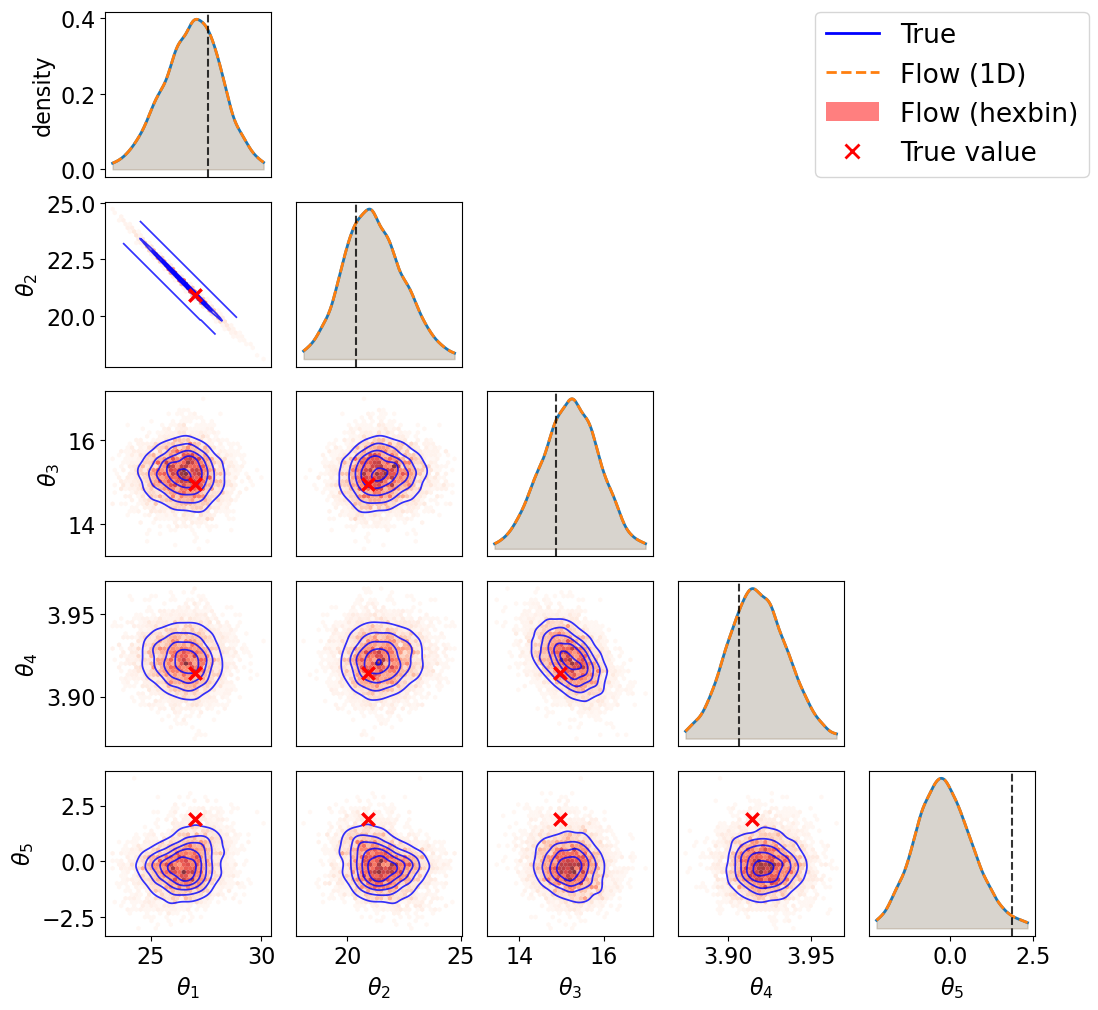

In [14]:
key = list(models_dict.keys())[0]
case = 2000
for key in models_dict.keys():
    print (key)
    fig = compare_posteriors_panels(
        models_dict[key]["params_generated"][case,:,:], models_dict[key]["params_generated"][case,:,:],
        labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$", r"$\theta_5$"],
        truths=models_dict[key]["params_true"][case,:],
        figsize=12,
        savepath=f'{key}.png'
    )
    plt.show()


(-0.1, 1.2)

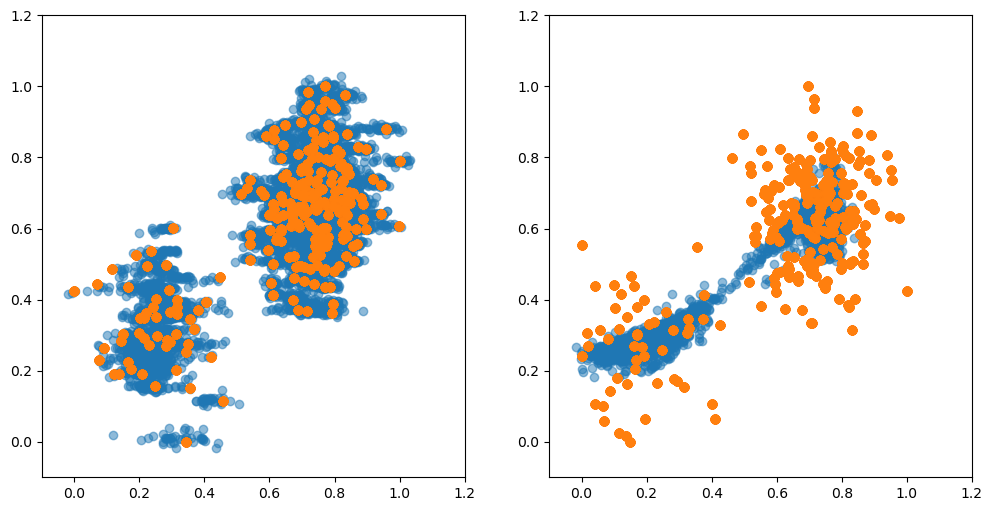

In [121]:
pm1 = 2
pm2 = 3
fig, ax = plt.subplots(1,2, figsize=(12,6))
# mean_smaple_1 = np.mean(x_samples_1,1)
key = keys[0]
x_true_1 = models_dict[key]["params_true"]
mean_smaple_1 = np.mean(models_dict[key]['params_generated'],axis=1)

_ = ax[0].scatter(mean_smaple_1[:,pm1], mean_smaple_1[:,pm2],alpha= 0.5)
_ = ax[0].scatter(x_true_1[:,pm1], x_true_1[:,pm2])
ax[0].set_xlim(-0.1,1.2)
ax[0].set_ylim(-0.1,1.2)

key = keys[-1]
x_true_1 = models_dict[key]["params_true"]
mean_smaple_1 = np.mean(models_dict[key]['params_generated'],axis=1)

_ = ax[1].scatter(mean_smaple_1[:,pm1], mean_smaple_1[:,pm2],alpha= 0.5)
_ = ax[1].scatter(x_true_1[:,pm1], x_true_1[:,pm2])
ax[1].set_xlim(-0.1,1.2)
ax[1].set_ylim(-0.1,1.2)


np.float32(35.874237)

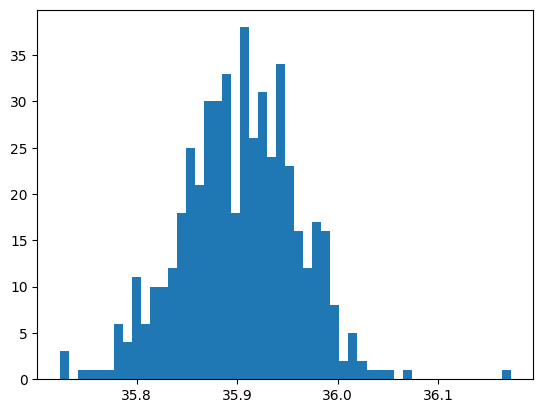

In [ ]:
x_samples.shape
_ = plt.hist(x_samples[140,:,1], bins = 50)
x_true[140,1]

In [ ]:
x_samples.shape
_ = plt.hist(x_samples[140,:,1], bins = 50)
x_true[140,1]

# Some summary

The parameter sigma is not well predicted. in fact the model gets the mean right but the distrubution is gaussianized!
Can we fix this problem? 
options to consider: 
change dt as sigma may appear only in fast time scale--> reducing dt from 10 to 5 (sample the trajectory every 5 time step) did not help
change T and dt --> change dt to 2 so we see the trajectory on much faster time steps and also reduce T to 30 (it was 100 before) as we may not neet to obserev the system for that long. 
Reducing dt to 2 imporve the prediction of sigma, but only slightly!
Making the model bigger helped a bit as well

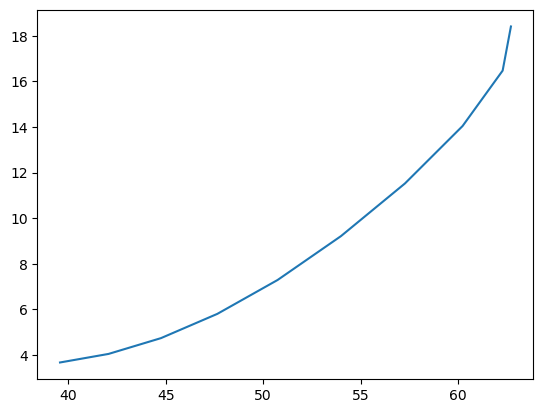

In [45]:
case = 30
plt.plot(models_dict[key]['conditionals'][case,:,2],models_dict[key]['conditionals'][case,:,0])